# 神经元的发放频率

## 0. 准备

In [54]:
import os

import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import csr_matrix
from tqdm.auto import tqdm, trange

# Color Palette
ColorBlue = [
    "#00B4FA",
    "#00A3E9",
    "#0093D9",
    "#0082C8",
    "#0071B7",
    "#0061A7",
    "#005096",
    "#003F85",
    "#002F75",
    "#001E64",
]
ColorRed = [
    "#FA5050",
    "#F24747",
    "#EA3E3E",
    "#E33535",
    "#DB2C2C",
    "#D32424",
    "#CB1B1B",
    "#C41212",
    "#BC0909",
    "#B40000",
]
ColorGreen = [
    "#96D250",
    "#85C850",
    "#75BE50",
    "#64B450",
    "#53AA50",
    "#43A050",
    "#329650",
    "#218C50",
    "#118250",
    "#007850",
]
ColorYellow = [
    "#FAFA00",
    "#FAE903",
    "#FAD907",
    "#FAC80A",
    "#FAB70D",
    "#FAA711",
    "#FA9614",
    "#FA8517",
    "#FA751B",
    "#FA641E",
]
ColorPurple = [
    "#FA82FA",
    "#E774E8",
    "#D465D6",
    "#C157C5",
    "#AE48B3",
    "#9C3AA1",
    "#892B8F",
    "#761D7E",
    "#630E6C",
    "#50005A",
]
ColorGray = [
    "#B4B4B4",
    "#A4A4A4",
    "#959595",
    "#858585",
    "#767676",
    "#666666",
    "#575757",
    "#474747",
    "#383838",
    "#282828",
]

## 1. LIF

In [ ]:
dt = 0.01 # ms
Time = 1000.0 # ms
T = int(Time/dt)
V_rest = -70.0 # Resting potential, unit: mV
V_reset = -60.0 # Reset potential, unit: mV
threshold = -50.0 # Threshold potential, unit: mV
t_ref = 2 # Refractory period, unit: ms
ref_length = int(t_ref/dt)
C = 500.0 # Capacitance, unit: pF
g_L = 25.0 # Leakage conductance, unit: nS

  0%|          | 0/19999 [00:00<?, ?it/s]

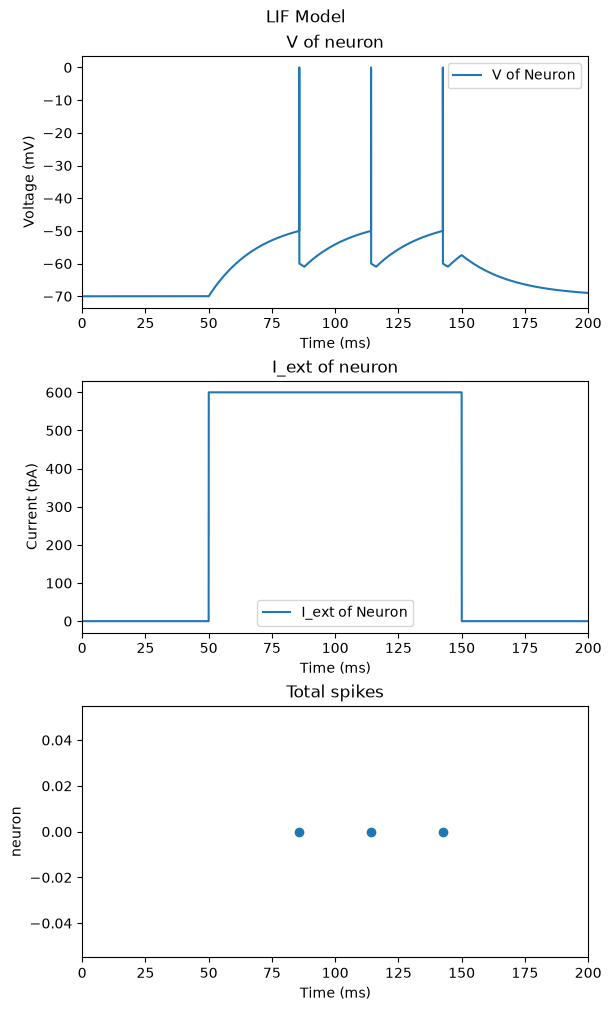

In [118]:
os.makedirs("pics", exist_ok=True)

N=1
Time_exp = 200.0 # ms
T_exp = int(Time_exp / dt)
V = np.full((N, T_exp), V_rest, dtype=np.float32)  # unit: mV

# A 
not_refractory = np.ones((N, T_exp), dtype=np.float32)

spikes = np.zeros((N, T_exp), dtype=np.float32)

I_ext = np.zeros(
    (N, T_exp), dtype=np.float32
)  # external current, unit: pA

t_start_pulse = 50 # unit: ms
t_end_pulse = 150 # unit: ms

I_ext[:, int(t_start_pulse / dt):int(t_end_pulse / dt)] = 600


for t in trange(1, T_exp):
    
    V[:, t] = V[:, t - 1] + dt * (
        -(V[:, t - 1] - V_rest) * g_L / C
        + (I_ext[:, t - 1]) * not_refractory[:, t - 1] / C
    )
    spikes[V[:, t] > threshold, t] = 1

    V[spikes[:, t] == 1, t - 1] = 0  # add a spike

    V[spikes[:, t] == 1, t] = V_reset  # reset the neuron

    # refractory_steps = np.clip((t+t_ref), a_min=None, a_max=T)
    refractory_steps = np.minimum(t + ref_length, T)
    not_refractory[spikes[:, t] == 1, t:refractory_steps] = 0

    

fig, axs = plt.subplots(3, 1, figsize=(6, 10), constrained_layout=True)

axs[0].set_title("V of neuron")
axs[0].set_xlabel("Time (ms)")
axs[0].set_ylabel("Voltage (mV)")
axs[0].set_xlim((0, Time_exp))
axs[1].set_title("I_ext of neuron")
axs[1].set_xlabel("Time (ms)")
axs[1].set_ylabel("Current (pA)")
axs[1].set_xlim((0, Time_exp))
axs[2].set_title("Total spikes")
axs[2].set_xlabel("Time (ms)")
axs[2].set_ylabel("neuron")
axs[2].set_xlim((0, Time_exp))



fig.suptitle(
    "LIF Model"
)


t = np.arange(T_exp) * dt
# plt.plot(t, I_ext[idx, :], label=f"I_ext of Neuron {idx}")
axs[0].plot(t, V[0, :], label="V of Neuron") 
axs[1].plot(t, I_ext[0, :], label="I_ext of Neuron")


axs[2].scatter(np.where(spikes == 1)[1] * dt, np.where(spikes == 1)[0])

axs[0].legend()
axs[1].legend()
plt.savefig("pics/lif.png", dpi=300)
plt.show()

## 2. AMPA

  0%|          | 0/99999 [00:00<?, ?it/s]

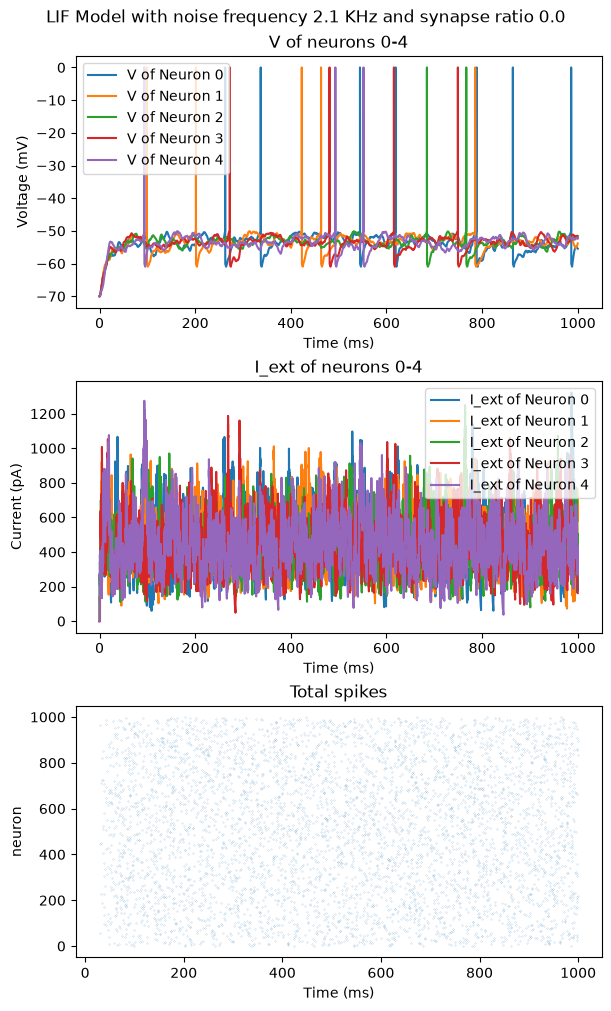

In [115]:
"""
    Ampa current
    Should follow the following equations:
    I_ampa = g_ampa * (V - V_E) * s_ampa
    where V_E = 0
    s is the gate here, it is between 0 and 1.
    and ds/dt = -s/tau_ampa + delta(t - t_spike)
    so basically it spikes when there is a spike and then decays exponentially to 0
    tau_ampa is about 2ms.
    """

g_ampa = 2.0 # AMPA conductance, unit: nS
tau_ampa = 2.0 # unit: ms
V_E = 0.0 # unit: mV
N = 1000
rng = np.random.default_rng()


V = np.full((N, T), V_rest)  # unit: mV

not_refractory = np.ones((N, T))
spikes = np.zeros((N, T))

I_ext = np.zeros((N, T))  # external current, unit: pA
# I_rec = np.zeros(
#     (N, T), dtype=np.float32
# )  # recurrent current, unit: pA
# W = np.zeros((N, N)) # synaptic weight. no units

S_ampa_ext = np.zeros((N, T))
# S_ampa_rec = np.zeros((N, T), dtype=np.float32)

synapse_ratio = 0.00

noise_freq = 2.1 # Noise frequency, unit: KHz
# You can try to modify this

p_noise = noise_freq * dt

spikes_external = rng.binomial(1, p_noise, (N, T))

# W = rng.binomial(1, synapse_ratio, (N, N)).astype(np.float32)
# W = np.zeros((N, N), dtype=np.float32)
# W = csr_matrix(rng.random((N, N)) < synapse_ratio, dtype=np.float32)


for t in trange(1, T):
    # print(f"Current time step: {t}")

    # V[:, t] = V[:, t - 1] + dt * (
    #     -(V[:, t - 1] - V_rest) * g_L / C
    #     + (I_ext[:, t - 1] + I_rec[:, t - 1]) * not_refractory[:, t - 1] / C
    # )
    V[:, t] = V[:, t - 1] + dt * (
        -(V[:, t - 1] - V_rest) * g_L / C
        + (I_ext[:, t - 1]) * not_refractory[:, t - 1] / C
    )
    spikes[V[:, t] > threshold, t] = 1

    V[spikes[:, t] == 1, t - 1] = 0  # add a spike

    V[spikes[:, t] == 1, t] = V_reset  # reset the neuron

    # refractory_steps = np.clip((t+t_ref), a_min=None, a_max=T)
    refractory_steps = np.minimum(t + ref_length, T)
    not_refractory[spikes[:, t] == 1, t:refractory_steps] = 0

    S_ampa_ext[:, t] = (
        S_ampa_ext[:, t - 1]
        - S_ampa_ext[:, t - 1] / tau_ampa * dt
        + spikes_external[:, t - 1]
    )
    I_ext[:, t] = g_ampa * -(V[:, t] - V_E) * S_ampa_ext[:, t]

    # S_ampa_rec[:, t] = (
    #     S_ampa_rec[:, t - 1] - S_ampa_rec[:, t - 1] / tau_ampa * dt + spikes[:, t - 1]
    # )
    # I_rec[:, t] = g_ampa * -(V[:, t] - V_E) * (W @ S_ampa_rec[:, t])

fig, axs = plt.subplots(3, 1, figsize=(6, 10), constrained_layout=True)

axs[0].set_title("V of neurons 0-4")
axs[0].set_xlabel("Time (ms)")
axs[0].set_ylabel("Voltage (mV)")
axs[1].set_title("I_ext of neurons 0-4")
axs[1].set_xlabel("Time (ms)")
axs[1].set_ylabel("Current (pA)")
axs[2].set_title("Total spikes")
axs[2].set_xlabel("Time (ms)")
axs[2].set_ylabel("neuron")

fig.suptitle(
    f"LIF Model with noise frequency {noise_freq} KHz and synapse ratio {synapse_ratio}"
)

for idx in range(5):
    t = np.arange(T) * dt
    # plt.plot(t, I_ext[idx, :], label=f"I_ext of Neuron {idx}")
    axs[0].plot(t, V[idx, :], label=f"V of Neuron {idx}")
    axs[1].plot(t, I_ext[idx, :], label=f"I_ext of Neuron {idx}")


axs[2].scatter(np.where(spikes == 1)[1] * dt, np.where(spikes == 1)[0], s=0.01)

axs[0].legend()
axs[1].legend()

plt.savefig(f"pics/lif_{noise_freq}KHz_synapse{synapse_ratio}.png", dpi=300)
plt.show()

## 在不同的频率下运行

In [ ]:
"""
Let's test it at different frequencies
"""

noise_freqs = np.arange(1.5, 3.05, 0.05)  # kHz
spike_freqs = np.zeros_like(noise_freqs) # Hz

for i in trange(len(noise_freqs), desc="Frequencies", position=0):
    p_noise = noise_freqs[i] * dt
    spikes_external = rng.binomial(1, p_noise, (N, T))
    V = np.full((N, T), V_rest)
    not_refractory = np.ones((N, T))
    spikes = np.zeros((N, T))
    I_ext = np.zeros((N, T))
    I_rec = np.zeros((N, T))
    p = 0.0
    W = csr_matrix(rng.random((N, N)) < p, dtype=np.float64)
    S_ampa_ext = np.zeros((N, T))
    S_ampa_rec = np.zeros((N, T))
    for t in trange(1, T, desc=f"Noise Frequency = {noise_freqs[i]:.02f}", position=1):
        V[:, t] = V[:, t - 1] + dt / C * (
            -g_L * (V[:, t - 1] - V_rest)
            - (I_ext[:, t - 1] + I_rec[:, t - 1]) * not_refractory[:, t - 1]
        )
        spikes[V[:, t] > threshold, t] = 1
        V[spikes[:, t] == 1, t - 1] = 0
        V[spikes[:, t] == 1, t] = V_reset
        refractory_steps = np.minimum(t + ref_length, T)
        not_refractory[spikes[:, t] == 1, t:refractory_steps] = 0
        S_ampa_ext[:, t] = (
            S_ampa_ext[:, t - 1]
            - S_ampa_ext[:, t - 1] / tau_ampa * dt
            + spikes_external[:, t - 1]
        )
        I_ext[:, t] = g_ampa * (V[:, t] - V_E) * S_ampa_ext[:, t]
        S_ampa_rec[:, t] = (
            S_ampa_rec[:, t - 1]
            - S_ampa_rec[:, t - 1] / tau_ampa * dt
            + spikes[:, t - 1]
        )
        I_rec[:, t] = g_ampa * (V[:, t] - V_E) * (W @ S_ampa_rec[:, t])
    # Average rate
    spike_freqs[i] = np.sum(spikes, axis=1).mean(axis=0) / Time * 1000 

# Save the artifacts
os.makedirs("data", exist_ok=True)
np.save("data/noise_freqs.npy", noise_freqs)
np.save("data/spike_freqs.npy", spike_freqs) 


反复运行上面的代码很耗时，所以我们在最后保存了两个数据。之后可以运行下面的代码直接读取文件。

In [104]:
noise_freqs: np.typing.NDArray = np.load("data/noise_freqs.npy")
spike_freqs: np.typing.NDArray = np.load("data/spike_freqs.npy")

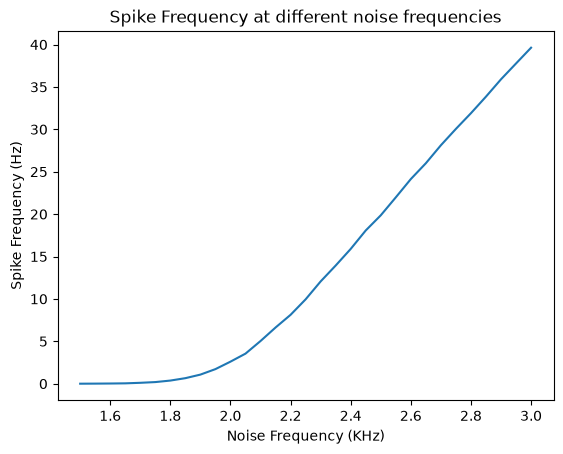

In [72]:
plt.title("Spike Frequency at different noise frequencies")
plt.xlabel("Noise Frequency (KHz)")
plt.ylabel("Spike Frequency (Hz)")
plt.plot(noise_freqs, spike_freqs)

## 3. 如果加入神经元内连接呢？

  0%|          | 0/99999 [00:00<?, ?it/s]

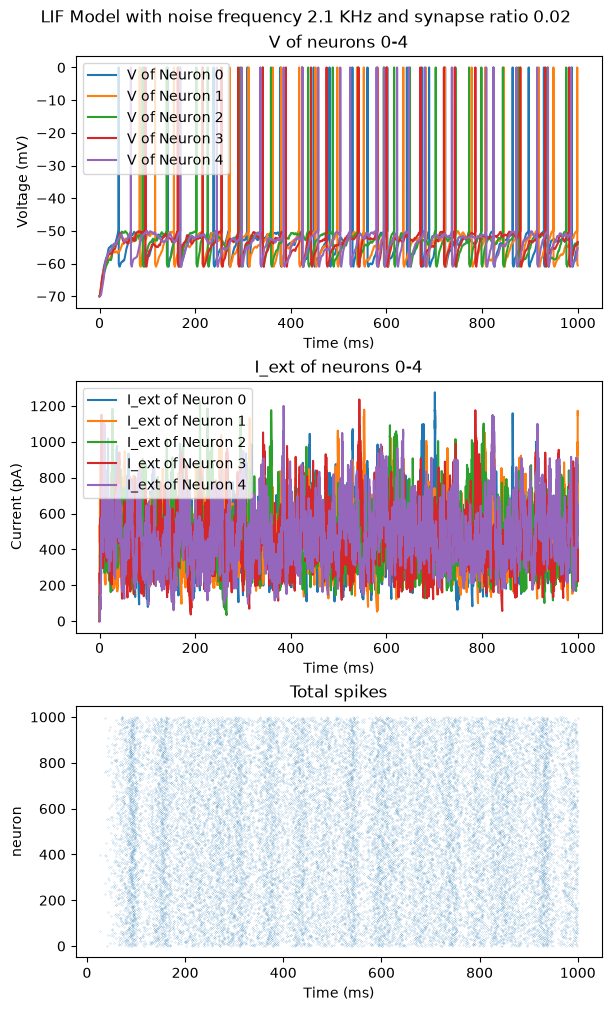

In [114]:
"""
Slightly Modify the previous code
"""

g_ampa = 2.0 # AMPA conductance, unit: nS
tau_ampa = 2.0 # unit: ms
V_E = 0.0 # unit: mV
N = 1000
rng = np.random.default_rng()


V = np.full((N, T), V_rest)  # unit: mV

not_refractory = np.ones((N, T))
spikes = np.zeros((N, T))

I_ext = np.zeros((N, T))  # external current, unit: pA
I_rec = np.zeros((N, T))  # recurrent current, unit: pA
# W = np.zeros((N, N)) # synaptic weight. no units

S_ampa_ext = np.zeros((N, T))
S_ampa_rec = np.zeros((N, T))

synapse_ratio = 0.02 # Change the synapse ratio for internal connects.

noise_freq = 2.1 # Noise frequency, unit: KHz
# You can try to modify this

p_noise = noise_freq * dt

spikes_external = rng.binomial(1, p_noise, (N, T))

# W = rng.binomial(1, synapse_ratio, (N, N)).astype(np.float32)
# W = np.zeros((N, N), dtype=np.float32)
W = csr_matrix(rng.random((N, N)) < synapse_ratio)


for t in trange(1, T):
    # print(f"Current time step: {t}")

    # V[:, t] = V[:, t - 1] + dt * (
    #     -(V[:, t - 1] - V_rest) * g_L / C
    #     + (I_ext[:, t - 1] + I_rec[:, t - 1]) * not_refractory[:, t - 1] / C
    # )
    V[:, t] = V[:, t - 1] + dt * (
        -(V[:, t - 1] - V_rest) * g_L / C
        + (I_ext[:, t - 1] + I_rec[:, t - 1]) * not_refractory[:, t - 1] / C
    )
    spikes[V[:, t] > threshold, t] = 1

    V[spikes[:, t] == 1, t - 1] = 0  # add a spike

    V[spikes[:, t] == 1, t] = V_reset  # reset the neuron

    # refractory_steps = np.clip((t+t_ref), a_min=None, a_max=T)
    refractory_steps = np.minimum(t + ref_length, T)
    not_refractory[spikes[:, t] == 1, t:refractory_steps] = 0

    S_ampa_ext[:, t] = (
        S_ampa_ext[:, t - 1]
        - S_ampa_ext[:, t - 1] / tau_ampa * dt
        + spikes_external[:, t - 1]
    )
    I_ext[:, t] = g_ampa * -(V[:, t] - V_E) * S_ampa_ext[:, t]

    # That is the entire reason we have this "useless" rec thing commented out
    S_ampa_rec[:, t] = (
        S_ampa_rec[:, t - 1]
         - S_ampa_rec[:, t - 1] / tau_ampa * dt
         + spikes[:, t - 1]
    )
    I_rec[:, t] = g_ampa * -(V[:, t] - V_E) * (W @ S_ampa_rec[:, t])

fig, axs = plt.subplots(3, 1, figsize=(6, 10), constrained_layout=True)

axs[0].set_title("V of neurons 0-4")
axs[0].set_xlabel("Time (ms)")
axs[0].set_ylabel("Voltage (mV)")
axs[1].set_title("I_ext of neurons 0-4")
axs[1].set_xlabel("Time (ms)")
axs[1].set_ylabel("Current (pA)")
axs[2].set_title("Total spikes")
axs[2].set_xlabel("Time (ms)")
axs[2].set_ylabel("neuron")

fig.suptitle(
    f"LIF Model with noise frequency {noise_freq} KHz and synapse ratio {synapse_ratio}"
)

for idx in range(5):
    t = np.arange(T) * dt
    # plt.plot(t, I_ext[idx, :], label=f"I_ext of Neuron {idx}")
    axs[0].plot(t, V[idx, :], label=f"V of Neuron {idx}")
    axs[1].plot(t, I_ext[idx, :], label=f"I_ext of Neuron {idx}")


axs[2].scatter(np.where(spikes == 1)[1] * dt, np.where(spikes == 1)[0], s=0.01)

axs[0].legend()
axs[1].legend()

plt.savefig(f"pics/lif_{noise_freq}KHz_synapse{synapse_ratio}.png", dpi=300)
plt.show()

理论预测

$$
\begin{cases}
y = f(x) \\
x = z + y \cdot N \cdot p
\end{cases}
$$

此处z为外部噪声，n为神经元数，p为连接概率。

理解起来很简单，就是输入为噪声+神经元的输出的平均输入。

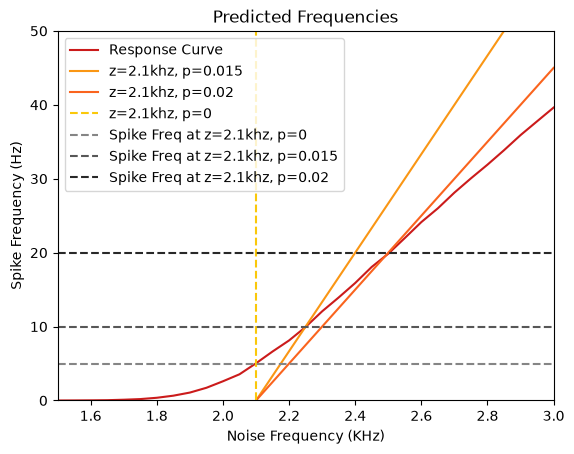

In [105]:
plt.xlim(1.5, 3)
plt.ylim(0, 50)
plt.xlabel("Noise Frequency (KHz)")
plt.ylabel("Spike Frequency (Hz)")

plt.plot(noise_freqs, spike_freqs, label="Response Curve", color=ColorRed[6])
def line(x: float, z: float, synapse_ratio: float, neuron_count: int) -> float:
    return (x-z) * 1000 / (neuron_count * synapse_ratio)


plt.plot(noise_freqs, line(noise_freqs, 2.1, 0.015, N), label="z=2.1khz, p=0.015", color=ColorYellow[6])
plt.plot(noise_freqs, line(noise_freqs, 2.1, 0.02, N), label="z=2.1khz, p=0.02", color=ColorYellow[9])
plt.vlines(2.1, 0, 50, label="z=2.1khz, p=0", linestyles="--", color=ColorYellow[3])

plt.hlines(5, 1.5, 3, colors=ColorGray[3], linestyles="--", label="Spike Freq at z=2.1khz, p=0")
plt.hlines(10, 1.5, 3, colors=ColorGray[6], linestyles="--", label="Spike Freq at z=2.1khz, p=0.015")
plt.hlines(20, 1.5, 3, colors=ColorGray[9], linestyles="--", label="Spike Freq at z=2.1khz, p=0.02")
plt.title("Predicted Frequencies")
plt.legend()

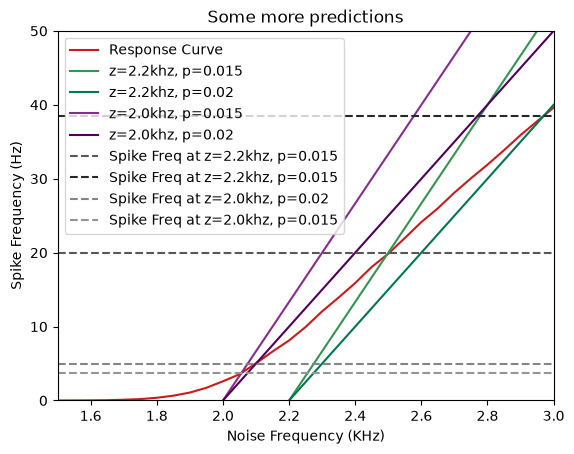

In [107]:
# Some more predictions exist but you can explore it yourself. Here is just an example. 
plt.title("Some more predictions")
plt.xlim(1.5, 3)
plt.ylim(0, 50)
plt.xlabel("Noise Frequency (KHz)")
plt.ylabel("Spike Frequency (Hz)")

plt.plot(noise_freqs, spike_freqs, label="Response Curve", color=ColorRed[6])

plt.plot(noise_freqs, line(noise_freqs, 2.2, 0.015, N), label="z=2.2khz, p=0.015", color=ColorGreen[6])
plt.plot(noise_freqs, line(noise_freqs, 2.2, 0.02, N), label="z=2.2khz, p=0.02", color=ColorGreen[9])
plt.plot(noise_freqs, line(noise_freqs, 2.0, 0.015, N), label="z=2.0khz, p=0.015", color=ColorPurple[6])
plt.plot(noise_freqs, line(noise_freqs, 2.0, 0.02, N), label="z=2.0khz, p=0.02", color=ColorPurple[9])

plt.hlines(20, 1.5, 3, colors=ColorGray[6], linestyles="--", label="Spike Freq at z=2.2khz, p=0.015")
plt.hlines(38.5, 1.5, 3, colors=ColorGray[9], linestyles="--", label="Spike Freq at z=2.2khz, p=0.015")
plt.hlines(5, 1.5, 3, colors=ColorGray[3], linestyles="--", label="Spike Freq at z=2.0khz, p=0.02")
plt.hlines(3.75, 1.5, 3, colors=ColorGray[2], linestyles="--", label="Spike Freq at z=2.0khz, p=0.015")

plt.legend()

此时我们做一个实验，来看看是否符合预测

Rep 0 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 1 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 2 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 3 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 4 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 5 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 6 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 7 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 8 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 9 start:   0%|          | 0/99999 [00:00<?, ?it/s]

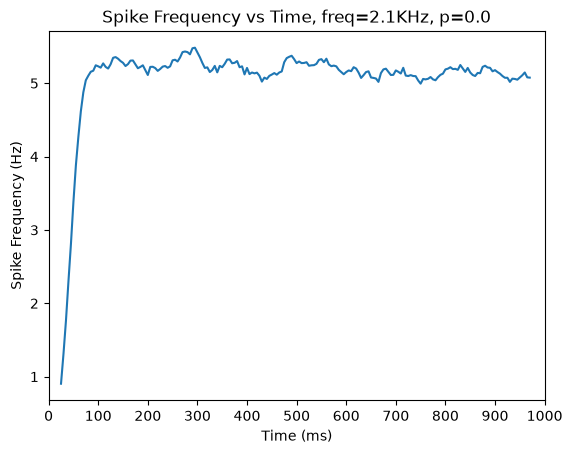

In [109]:
Rep = 10
# Noise ratio

noise_freq = 2.1

p_noise = noise_freq * dt
# synapse ratio
p = 0.0

window_size = int(50 / dt)
shift_size = int(5 / dt)
x = np.arange(window_size // 2, T - window_size // 2, shift_size)
spike_freqs_exp = np.zeros((Rep, len(x)))


for rep in range(Rep):
    spikes_external = rng.binomial(1, p_noise, (N, T))
    V = np.full((N, T), V_rest)
    not_refractory = np.ones((N, T))
    spikes = np.zeros((N, T))
    I_ext = np.zeros((N, T))
    I_rec = np.zeros((N, T))
    W = csr_matrix(rng.random((N, N)) < p, dtype=np.float32)
    S_ampa_ext = np.zeros((N, T))
    S_ampa_rec = np.zeros((N, T))
    
    for t in trange(1, T, desc=f"Rep {rep} start"):
        V[:, t] = V[:, t - 1] + dt / C * (
            -g_L * (V[:, t - 1] - V_rest)
            - (I_ext[:, t - 1] + I_rec[:, t - 1]) * not_refractory[:, t - 1]
        )
        spikes[V[:, t] > threshold, t] = 1
        V[spikes[:, t] == 1, t - 1] = 0
        V[spikes[:, t] == 1, t] = V_reset
        refractory_steps = np.minimum(t + ref_length, T)
        not_refractory[spikes[:, t] == 1, t:refractory_steps] = 0
        S_ampa_ext[:, t] = (
            S_ampa_ext[:, t - 1]
            - S_ampa_ext[:, t - 1] / tau_ampa * dt
            + spikes_external[:, t - 1]
        )
        I_ext[:, t] = g_ampa * (V[:, t] - V_E) * S_ampa_ext[:, t]
        S_ampa_rec[:, t] = (
            S_ampa_rec[:, t - 1]
            - S_ampa_rec[:, t - 1] / tau_ampa * dt
            + spikes[:, t - 1]
        )
        I_rec[:, t] = g_ampa * (V[:, t] - V_E) * (W @ S_ampa_rec[:, t])
    for i, t in enumerate(x):
        spike_freqs_exp[rep, i] = (
            np.sum(spikes[:, t-window_size // 2 : t + window_size // 2], axis=1).mean(axis=0) / 50 * 1000
        )

plt.plot(x, np.mean(spike_freqs_exp, axis=0))
plt.xlim(0, T)
plt.xticks(np.arange(0, T + 1, int(T / 10)), np.arange(0, 1001, 100))
plt.xlabel("Time (ms)")
plt.ylabel("Spike Frequency (Hz)")
plt.title(f"Spike Frequency vs Time, freq={p_noise / dt}KHz, p={p}")
plt.savefig(f"pics/spike_freq_{noise_freq}khz_synapse_{p}.png", dpi=300)

可以看出是大致符合预测的。
至于为什么noise=2.2khz, p=0.015反而略低于noise=2.1khz, p=0.02，这是因为上面的公式假定神经元的发放是独立的，但其实往往不是，神经元会倾向于一起发放。可以试着[在这个板块](#3-如果加入神经元内连接呢)用这两个参数运行。会看到一些竖线。这就说明有大量神经元在一起发放动作电位。这会导致实际发放率略高于预测值。

### 稳定性测试

Rep 0 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 1 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 2 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 3 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 4 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 5 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 6 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 7 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 8 start:   0%|          | 0/99999 [00:00<?, ?it/s]

Rep 9 start:   0%|          | 0/99999 [00:00<?, ?it/s]

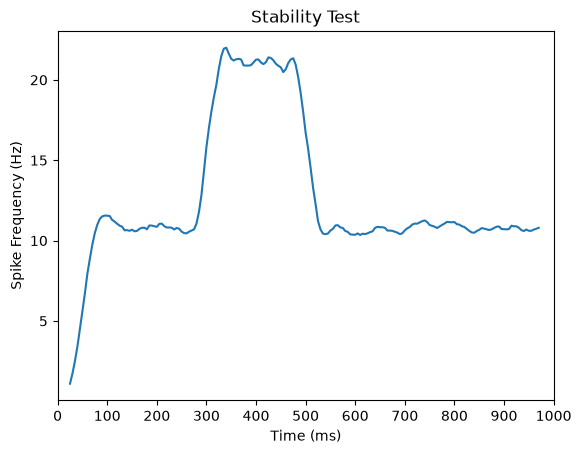

In [ ]:
Rep = 10
# Noise ratio

noise_freq = 2.1
test_noise_freq = 2.2

# p_noise = noise_freq * dt
p_noise = np.full((T, ), noise_freq * dt)
t_start_pulse = 300
t_end_pulse = 500
p_noise[int(t_start_pulse / dt) : int(t_end_pulse / dt)] = test_noise_freq * dt
# synapse ratio
p = 0.015

window_size = int(50 / dt)
shift_size = int(5 / dt)
x = np.arange(window_size // 2, T - window_size // 2, shift_size)
spike_freqs_exp = np.zeros((Rep, len(x)))


for rep in range(Rep):
    spikes_external = rng.binomial(1, p_noise, (N, T))
    V = np.full((N, T), V_rest)
    not_refractory = np.ones((N, T))
    spikes = np.zeros((N, T))
    I_ext = np.zeros((N, T))
    I_rec = np.zeros((N, T))
    W = csr_matrix(rng.random((N, N)) < p, dtype=np.float32)
    S_ampa_ext = np.zeros((N, T))
    S_ampa_rec = np.zeros((N, T))
    
    for t in trange(1, T, desc=f"Rep {rep} start"):
        V[:, t] = V[:, t - 1] + dt / C * (
            -g_L * (V[:, t - 1] - V_rest)
            - (I_ext[:, t - 1] + I_rec[:, t - 1]) * not_refractory[:, t - 1]
        )
        spikes[V[:, t] > threshold, t] = 1
        V[spikes[:, t] == 1, t - 1] = 0
        V[spikes[:, t] == 1, t] = V_reset
        refractory_steps = np.minimum(t + ref_length, T)
        not_refractory[spikes[:, t] == 1, t:refractory_steps] = 0
        S_ampa_ext[:, t] = (
            S_ampa_ext[:, t - 1]
            - S_ampa_ext[:, t - 1] / tau_ampa * dt
            + spikes_external[:, t - 1]
        )
        I_ext[:, t] = g_ampa * (V[:, t] - V_E) * S_ampa_ext[:, t]
        S_ampa_rec[:, t] = (
            S_ampa_rec[:, t - 1]
            - S_ampa_rec[:, t - 1] / tau_ampa * dt
            + spikes[:, t - 1]
        )
        I_rec[:, t] = g_ampa * (V[:, t] - V_E) * (W @ S_ampa_rec[:, t])
    for i, t in enumerate(x):
        spike_freqs_exp[rep, i] = (
            np.sum(spikes[:, t-window_size // 2 : t + window_size // 2], axis=1).mean(axis=0) / 50 * 1000
        )

plt.plot(x, np.mean(spike_freqs_exp, axis=0))
plt.xlim(0, T)
plt.xticks(np.arange(0, T + 1, int(T / 10)), np.arange(0, 1001, 100))
plt.xlabel("Time (ms)")
plt.ylabel("Spike Frequency (Hz)")
plt.title("Stability Test")
plt.savefig("pics/stability_test.png", dpi=300)